In [1]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import MaxNLocator

FIG_DIR = Path("../../fig/H7")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "Libertinus Serif",
    "font.size": CORPS,
    "axes.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


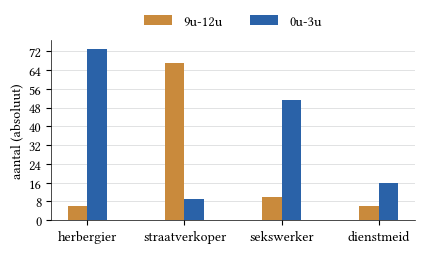

In [2]:
# Absolute aantallen per beroep, voormiddag vs. na middernacht (eerste wijk)
df_dagdeel = pd.DataFrame({
    "beroep":  ["herbergier", "straatverkoper", "sekswerker", "dienstmeid"],
    "9u-12u":  [6, 67, 10, 6],
    "0u-3u":   [73, 9, 51, 16],
})

KLEUR = {"9u-12u": KLEUR_DAG, "0u-3u": KLEUR_NACHT}
bar_width = 0.2
x = range(len(df_dagdeel))

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.55))
ax.bar([p - bar_width/2 for p in x], df_dagdeel["9u-12u"],
       width=bar_width, label="9u-12u", color=KLEUR["9u-12u"])
ax.bar([p + bar_width/2 for p in x], df_dagdeel["0u-3u"],
       width=bar_width, label="0u-3u", color=KLEUR["0u-3u"])

# dunne kaderlijnen rondom
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

# assen
ax.set_xticks(list(x))
ax.set_xticklabels(df_dagdeel["beroep"])
ax.yaxis.grid(True)
ax.set_ylabel("aantal (absoluut)")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))   # gehele getallen op y-as

# legende boven de grafiek, zodat de figuur 108 mm breed blijft
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)

pas_breedte_aan(fig, tight=True)
fig.savefig(FIG_DIR / "7.6_beroepen_dagdeel.png", dpi=300,
            transparent=True, bbox_inches="tight")
plt.show()

In [3]:
# ── Registratieredenen na middernacht in de eerste wijk (slot §7.4) ─────────
# Steekproefdatabank, wijk 1, personen geregistreerd tussen 0u en 3u.
MESO = Path("../../data/algemeen/gebeurtenisdata_meso/steekproefdatabank.xlsx")
meso = pd.read_excel(MESO)
meso["uur"] = pd.to_numeric(meso["hour_processed"].astype(str).str.extract(r"^(\d{1,2})")[0], errors="coerce")
meso["subcat"] = meso["subcategory"].astype(str).str.strip().str.lower()
nacht_w1 = meso[(meso["district"].astype(str) == "1") & meso["uur"].isin([0, 1, 2])]

def aandelen(reeks, n_top=6):
    return (reeks.value_counts(normalize=True) * 100).round(1).head(n_top)

vrouwen = nacht_w1[nacht_w1["gender"] == "woman"]
mannen = nacht_w1[nacht_w1["gender"] == "man"]
print(f"vrouwen (n={len(vrouwen)}), subcategorie (%):")
print(aandelen(vrouwen["subcat"]).to_string(), "\n")
print(f"mannen (n={len(mannen)}), subcategorie (%):")
print(aandelen(mannen["subcat"]).to_string(), "\n")

VRIJE_TIJD = ["dronkenschap", "nachtlawaai", "fysiek geweld", "wanorder"]
vrouwen_vrij = vrouwen[vrouwen["subcat"].isin(VRIJE_TIJD)]
print(f"vrouwen met dronkenschap, nachtlawaai, geweld of wanorde (n={len(vrouwen_vrij)}), beroep (%):")
print(aandelen(vrouwen_vrij["profession"].astype(str).str.strip().str.lower()).to_string())


vrouwen (n=160), subcategorie (%):
subcat
entertainment    38.1
nachtlawaai      23.8
dronkenschap     11.2
zeden             9.4
wanorder          7.5
diefstal          3.8 

mannen (n=174), subcategorie (%):
subcat
dronkenschap        23.0
entertainment       12.1
nachtlawaai         12.1
wanorder            11.5
dienstmededeling    10.3
fysiek geweld        7.5 

vrouwen met dronkenschap, nachtlawaai, geweld of wanorde (n=69), beroep (%):
profession
lichtmeisje       36.2
koetsier          13.0
nan               11.6
werkvrouw         10.1
herbergierster     7.2
herbergier         4.3
